# Practical No. 05: AI Image Generation for Smart Agriculture Using Stable Diffusion

**Course:** 2311312T / 2311312L 2026–27 — Lab Graded Assignments  
**Student name:** Rushikesh Hande  
**PRN:** 202401110056  
**Date:** 31-10-2026

## Aim
To generate useful smart-agriculture images using a pretrained Stable Diffusion model and study how prompts, negative prompts, inference steps, guidance scale, and scheduler choice affect the generated images.

## Objectives
1. Load and use a pretrained text-to-image diffusion model.
2. Understand the main parts of the Stable Diffusion pipeline.
3. Create an agriculture prompt dataset for different farming situations.
4. Generate images of smart farming, irrigation, greenhouses, and agricultural drones.
5. Compare negative prompts, inference steps, guidance scale, and two schedulers.
6. Record generation time and discuss the results using the generated images.


## 1. Theory

### What is Stable Diffusion?
Stable Diffusion is a text-to-image AI model. It creates an image from a written description called a prompt. It starts with random noise and gradually changes that noise into an image that matches the prompt. It works in a compressed representation called latent space. A Variational Autoencoder (VAE) decoder converts the final representation into a normal image.

### Application: Smart agriculture
In this practical, I use Stable Diffusion to create sample visual concepts for smart agriculture. These images can help explain modern farming ideas such as drone-based crop monitoring, drip irrigation, greenhouse farming, and automated harvesting. The generated images are illustrative concepts; they are not real field observations and cannot be used as proof of crop health.

### Main pipeline components

| Component | Function |
|---|---|
| **Tokenizer and text encoder** | Convert my written prompt into numerical information that the model can understand. |
| **U-Net denoiser** | Predict and remove noise from the image representation during generation. |
| **Scheduler** | Decide how the noisy representation is updated at each generation step. |
| **VAE** | Convert the final compressed representation into a visible image. |
| **Classifier-free guidance** | Control how strongly the generated image follows my text prompt. |

### Parameters investigated
- **Prompt:** The description I give to the model.
- **Negative prompt:** Things I do not want in the generated image.
- **Inference steps:** How many denoising steps the model performs.
- **Guidance scale:** How strongly the model follows my prompt.
- **Scheduler:** The method used to update the image during denoising.

### Why I use a prompt dataset
I prepare a small dataset of agriculture-related prompts. Each row contains a farming topic and a detailed description. This keeps my experiments organised and lets me generate images for different smart-agriculture applications using the same model.


In [ ]:
# I install the required libraries for Stable Diffusion.
# I use pandas 2.2.3 to avoid conflicts with Google Colab.
%pip -q install --upgrade diffusers transformers accelerate safetensors matplotlib "pandas==2.2.3"

In [ ]:
# I import os to work with folders and file paths.
import os
# I import time to measure how long image generation takes.
import time
# I import json to store or work with structured settings if needed.
import json
# I import zipfile so I can package output files when required.
import zipfile
# I import gc to clear unused memory after heavy model operations.
import gc
# I use Path to create and manage output folders easily.
from pathlib import Path

# I import PyTorch because the Stable Diffusion model runs using tensors and GPU/CPU.
import torch
# I use pandas to create and manage my agriculture prompt dataset and result tables.
import pandas as pd
# I use matplotlib to display charts if I want to compare experiment results.
import matplotlib.pyplot as plt
# I use display and Markdown to show images and formatted text inside the notebook.
from IPython.display import display, Markdown
# I import the Stable Diffusion pipeline to generate images from text prompts.
# I import two schedulers so I can compare their image-generation behaviour.
from diffusers import (
    StableDiffusionPipeline,
    DDIMScheduler,
    DPMSolverMultistepScheduler,
)

# I select the pretrained Stable Diffusion 1.5 model from Hugging Face.
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
# I create a folder where my generated agriculture images and result files will be saved.
OUTPUT_DIR = Path("smart_agriculture_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# I check whether a GPU is available. If not, I use the CPU.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# I use float16 on GPU to reduce memory use, and float32 on CPU for compatibility.
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

print(f"Device: {DEVICE}")
print(f"Torch version: {torch.__version__}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: No GPU detected. Image generation may be very slow; use a Colab GPU runtime if possible.")

# I keep these base settings fixed so that my comparisons are fair.
BASE_SEED = 2026
BASE_STEPS = 20
BASE_GUIDANCE = 7.5
IMAGE_WIDTH = 512
IMAGE_HEIGHT = 512
# I list unwanted visual problems that I want the model to avoid.
NEGATIVE_PROMPT = "blurry, low quality, distorted, unrealistic machinery, deformed objects, text, watermark, logo"

print("Output directory:", OUTPUT_DIR.resolve())


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Device: cuda
Torch version: 2.11.0+cu130
GPU: Tesla T4
Output directory: /content/smart_agriculture_outputs


## 3. Load the pretrained Stable Diffusion pipeline

I load the pretrained model and move it to the available device. The pipeline connects the tokenizer, text encoder, U-Net, scheduler, and VAE. If model access fails, I check the model ID, internet connection, model access requirements, and available runtime memory.


In [ ]:
# I load the pretrained model and choose the data type based on my device.
pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=DTYPE,
    use_safetensors=True,
)
# I move the model to my GPU or CPU so I can generate images.
pipe = pipe.to(DEVICE)
pipe.set_progress_bar_config(disable=False)

# I save the original scheduler settings so I can compare schedulers fairly.
BASE_SCHEDULER = pipe.scheduler
BASE_SCHEDULER_CONFIG = BASE_SCHEDULER.config

print("Model loaded successfully.")
print("Tokenizer:", type(pipe.tokenizer).__name__)
print("Text encoder:", type(pipe.text_encoder).__name__)
print("U-Net:", type(pipe.unet).__name__)
print("Scheduler:", type(pipe.scheduler).__name__)
print("VAE:", type(pipe.vae).__name__)
print("VAE scale factor:", pipe.vae_scale_factor)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Model loaded successfully.
Tokenizer: CLIPTokenizer
Text encoder: CLIPTextModel
U-Net: UNet2DConditionModel
Scheduler: PNDMScheduler
VAE: AutoencoderKL
VAE scale factor: 8


## 4. Reusable image-generation function

I create one function so I do not have to write the same generation code again and again. It takes a prompt and settings, generates an image, measures the time, saves the image, and records the experiment details.


In [ ]:
# I store the settings and time for every image so I can compare them later.
experiment_records = []

def generate_image(
    prompt,
    *,
    negative_prompt=NEGATIVE_PROMPT,
    steps=BASE_STEPS,
    guidance=BASE_GUIDANCE,
    seed=BASE_SEED,
    group="general",
    tag="image",
    scheduler_cls=None,
):
    """Generate, save, time, and record one image."""
    # I remember the current scheduler so I can restore it after this experiment.
    previous_scheduler = pipe.scheduler
    scheduler_label = type(previous_scheduler).__name__
    if scheduler_cls is not None:
        pipe.scheduler = scheduler_cls.from_config(BASE_SCHEDULER_CONFIG)
        scheduler_label = scheduler_cls.__name__

    # I use a fixed seed to make comparisons more controlled.
    generator = torch.Generator(device=DEVICE).manual_seed(int(seed))
    # I start the timer before generating the image.
    started = time.perf_counter()
    try:
        with torch.inference_mode():
            result = pipe(
                prompt=prompt,
                negative_prompt=negative_prompt if negative_prompt else None,
                num_inference_steps=int(steps),
                guidance_scale=float(guidance),
                width=IMAGE_WIDTH,
                height=IMAGE_HEIGHT,
                generator=generator,
            )
        # I take the first generated image from the model output.
        image = result.images[0]
        elapsed = time.perf_counter() - started
        safe_tag = "".join(ch if ch.isalnum() or ch in "-_" else "_" for ch in tag)
        filename = f"{group}_{safe_tag}.png"
        filepath = OUTPUT_DIR / filename
        image.save(filepath)
        experiment_records.append({
            "experiment": group,
            "tag": tag,
            "prompt": prompt,
            "negative_prompt": negative_prompt or "(none)",
            "steps": int(steps),
            "guidance_scale": float(guidance),
            "seed": int(seed),
            "scheduler": scheduler_label,
            "width": IMAGE_WIDTH,
            "height": IMAGE_HEIGHT,
            "time_seconds": round(elapsed, 2),
            "image_file": str(filepath),
        })
        return image, elapsed
    finally:
        pipe.scheduler = previous_scheduler
        if DEVICE == "cuda":
            torch.cuda.empty_cache()


def show_image(image, title):
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")
    plt.show()

print("Generation function ready.")

Generation function ready.


## 5. Experiment A — agriculture prompt dataset

I create a small prompt dataset with different smart-agriculture topics. I use the same inference steps, guidance scale, seed, and negative prompt for each row. This helps me focus on how the written prompt changes the generated image.


,topic,prompt
0,drone_monitoring,A modern agricultural drone flying above a lar...
1,drip_irrigation,A close view of a drip irrigation system water...
2,smart_greenhouse,A modern smart greenhouse with rows of healthy...
3,automated_harvesting,A modern agricultural harvesting machine worki...


  0%|          | 0/20 [00:00<?, ?it/s]

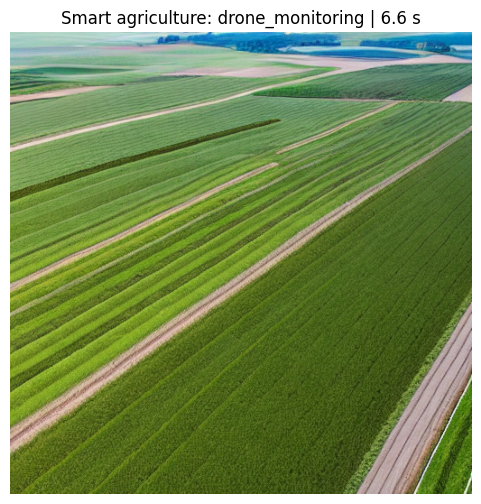

Prompt: A modern agricultural drone flying above a large healthy green crop field, monitoring rows of crops, sunny morning, realistic farming photography, detailed landscape 



  0%|          | 0/20 [00:00<?, ?it/s]

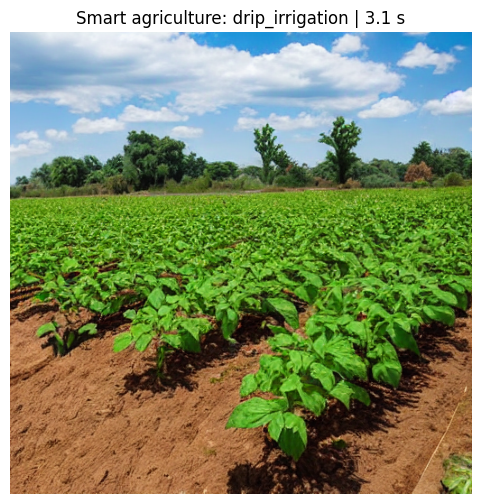

Prompt: A close view of a drip irrigation system watering rows of tomato plants on a farm, water drops near the roots, efficient water use, bright natural daylight, realistic agricultural photography 



  0%|          | 0/20 [00:00<?, ?it/s]

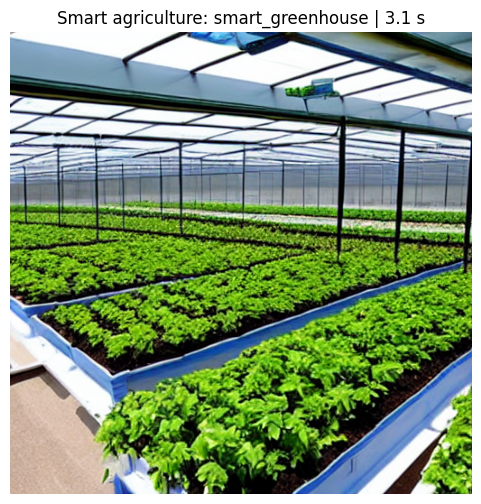

Prompt: A modern smart greenhouse with rows of healthy vegetable plants, transparent roof, automated watering pipes and sensors, clean organised farming environment, realistic photography 



  0%|          | 0/20 [00:00<?, ?it/s]

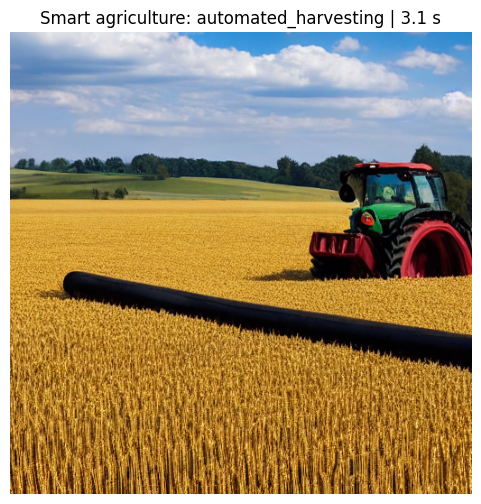

Prompt: A modern agricultural harvesting machine working carefully in a golden wheat field, wide rural landscape, clear daylight, realistic documentary photography 



In [ ]:
# I create a small dataset of text prompts for smart-agriculture applications.
agriculture_dataset = pd.DataFrame([
    {
        "topic": "drone_monitoring",
        "prompt": "A modern agricultural drone flying above a large healthy green crop field, monitoring rows of crops, sunny morning, realistic farming photography, detailed landscape"
    },
    {
        "topic": "drip_irrigation",
        "prompt": "A close view of a drip irrigation system watering rows of tomato plants on a farm, water drops near the roots, efficient water use, bright natural daylight, realistic agricultural photography"
    },
    {
        "topic": "smart_greenhouse",
        "prompt": "A modern smart greenhouse with rows of healthy vegetable plants, transparent roof, automated watering pipes and sensors, clean organised farming environment, realistic photography"
    },
    {
        "topic": "automated_harvesting",
        "prompt": "A modern agricultural harvesting machine working carefully in a golden wheat field, wide rural landscape, clear daylight, realistic documentary photography"
    },
])

# I display my dataset before generating images so I can check its topics and prompts.
display(agriculture_dataset)

# I generate one image for every prompt in my dataset.
for _, row in agriculture_dataset.iterrows():
    img, seconds = generate_image(
        row["prompt"],
        steps=BASE_STEPS,
        guidance=BASE_GUIDANCE,
        seed=BASE_SEED,
        group="agriculture_dataset",
        tag=row["topic"],
    )
    show_image(img, f"Smart agriculture: {row['topic']} | {seconds:.1f} s")
    print("Prompt:", row["prompt"], "\n")


### Observation — agriculture prompt dataset

After viewing the generated images, I check whether each image represents its farming topic. I note visible objects such as drones, irrigation pipes, greenhouse structures, crops, and harvesting machines. The model may not show every detail exactly as I described it.


## 6. Experiment B — effect of a negative prompt

I use the same smart-agriculture prompt, seed, inference steps, and guidance scale. I change only the negative prompt. I compare the two outputs to see whether the negative prompt reduces unwanted details.


  0%|          | 0/20 [00:00<?, ?it/s]

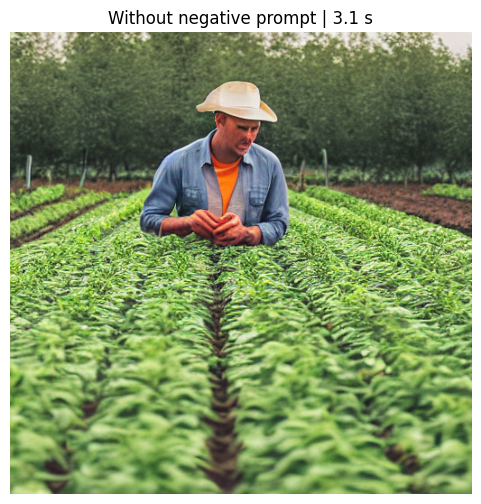

  0%|          | 0/20 [00:00<?, ?it/s]

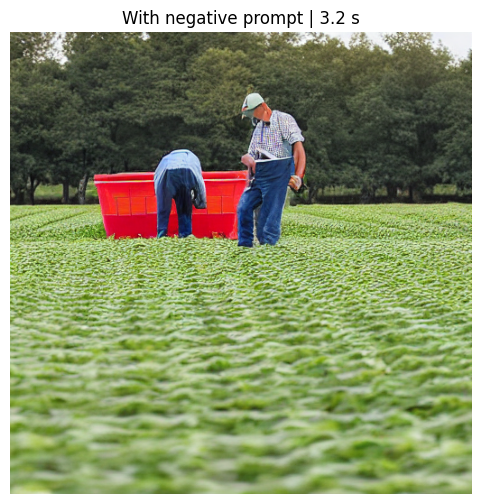

I compare the clarity, unwanted details, and match with my prompt. A negative prompt can reduce listed features, but it cannot guarantee that they will disappear.


In [ ]:
# I use the same farm scene in both tests so that I can compare the effect of a negative prompt.
negative_test_prompt = (
    "A realistic photograph of a farmer inspecting healthy tomato plants in a green farm, "
    "rows of crops, natural daylight, clear details, professional agricultural photography"
)

# I generate the first image without giving any negative prompt.
img_no_negative, time_no_negative = generate_image(
    negative_test_prompt,
    negative_prompt="",
    steps=BASE_STEPS,
    guidance=BASE_GUIDANCE,
    seed=314,
    group="negative_prompt",
    tag="without_negative_prompt",
)
show_image(img_no_negative, f"Without negative prompt | {time_no_negative:.1f} s")

# I generate the second image with unwanted features listed in the negative prompt.
img_with_negative, time_with_negative = generate_image(
    negative_test_prompt,
    negative_prompt="blurry, low quality, distorted plants, malformed hands, extra fingers, text, watermark, logo",
    steps=BASE_STEPS,
    guidance=BASE_GUIDANCE,
    seed=314,
    group="negative_prompt",
    tag="with_negative_prompt",
)
show_image(img_with_negative, f"With negative prompt | {time_with_negative:.1f} s")

print("I compare the clarity, unwanted details, and match with my prompt. A negative prompt can reduce listed features, but it cannot guarantee that they will disappear.")


## 7. Experiment C — effect of inference steps

I use the same smart-farming prompt and seed with 10, 20, and 30 inference steps. I record the generation time and compare the details. More steps usually take more time, but the image quality may not improve by the same amount.


  0%|          | 0/10 [00:00<?, ?it/s]

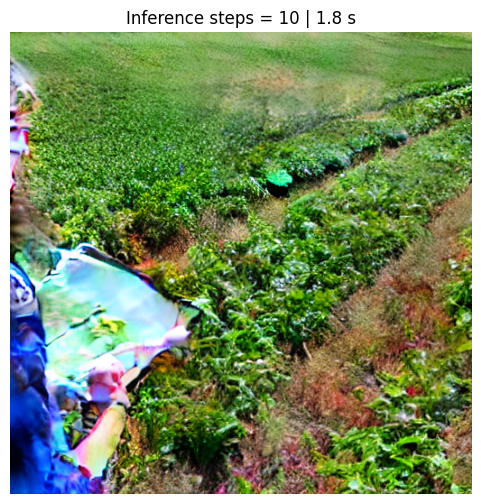

  0%|          | 0/20 [00:00<?, ?it/s]

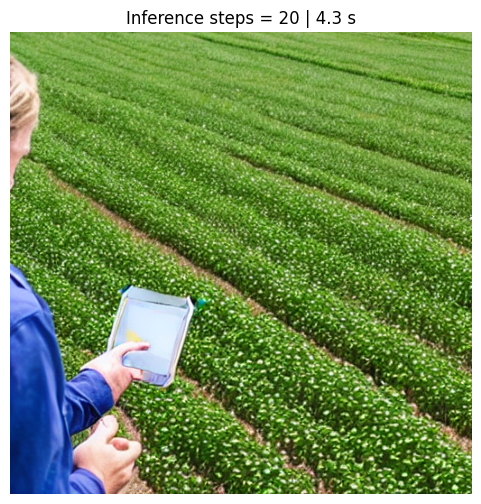

  0%|          | 0/30 [00:00<?, ?it/s]

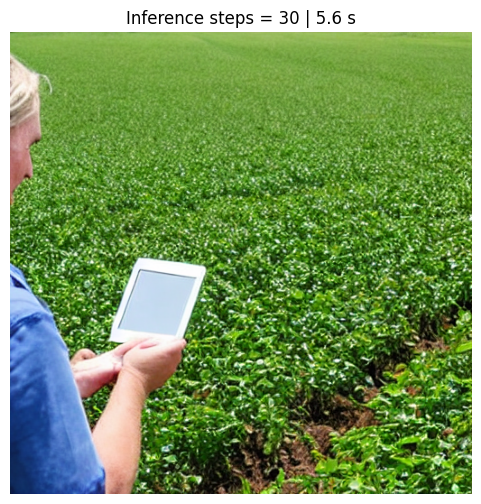

In [ ]:
# I choose a prompt showing a farmer using a digital tablet in a crop field.
steps_prompt = (
    "A farmer standing in a green crop field and checking crop information on a digital tablet, "
    "modern precision agriculture, clear sky, realistic photography, natural colours and fine details"
)

# I change only the number of inference steps in this experiment.
for steps_value in [10, 20, 30]:
    img, seconds = generate_image(
        steps_prompt,
        steps=steps_value,
        guidance=BASE_GUIDANCE,
        seed=808,
        group="inference_steps",
        tag=f"steps_{steps_value}",
    )
    show_image(img, f"Inference steps = {steps_value} | {seconds:.1f} s")


## 8. Experiment D — effect of guidance scale

I use one prompt, the same seed, and the same number of inference steps. I compare guidance scales 3.0, 7.5, and 12.0. I observe how closely the image follows my description and whether a high guidance value creates unnatural details.


  0%|          | 0/20 [00:00<?, ?it/s]

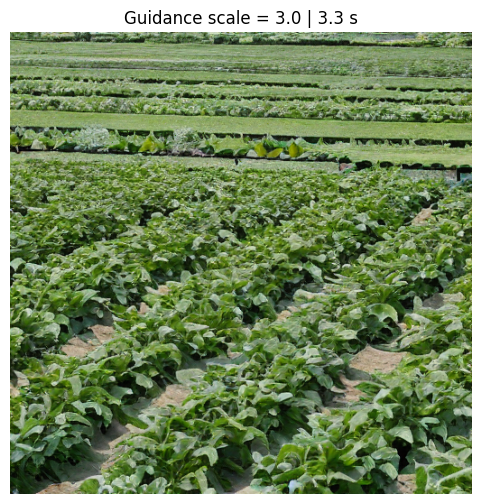

  0%|          | 0/20 [00:00<?, ?it/s]

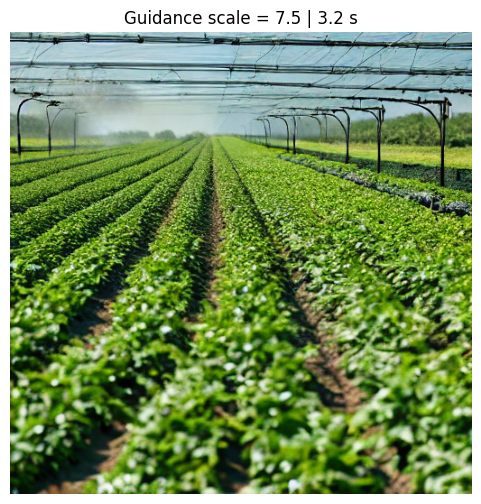

  0%|          | 0/20 [00:00<?, ?it/s]

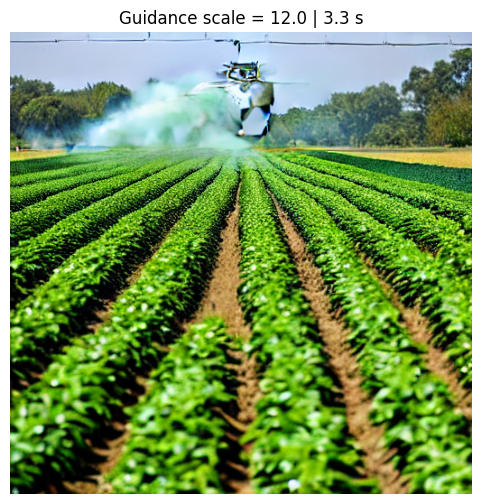

In [ ]:
# I use a prompt about a smart irrigation system for this comparison.
guidance_prompt = (
    "A smart irrigation system watering neat rows of green vegetable crops, "
    "visible water pipes and sprinklers, a modern sustainable farm, realistic photography, balanced composition"
)

# I change only the guidance scale and keep the other settings fixed.
for guidance_value in [3.0, 7.5, 12.0]:
    img, seconds = generate_image(
        guidance_prompt,
        steps=BASE_STEPS,
        guidance=guidance_value,
        seed=909,
        group="guidance_scale",
        tag=f"guidance_{str(guidance_value).replace('.', '_')}",
    )
    show_image(img, f"Guidance scale = {guidance_value} | {seconds:.1f} s")


## 9. Experiment E — scheduler comparison

I compare DDIM and DPM-Solver using the same agriculture prompt, seed, guidance scale, image size, and inference steps. I check their generation time and visual results. Different schedulers may produce different results, and one scheduler is not always best for every model and prompt.


  0%|          | 0/20 [00:00<?, ?it/s]

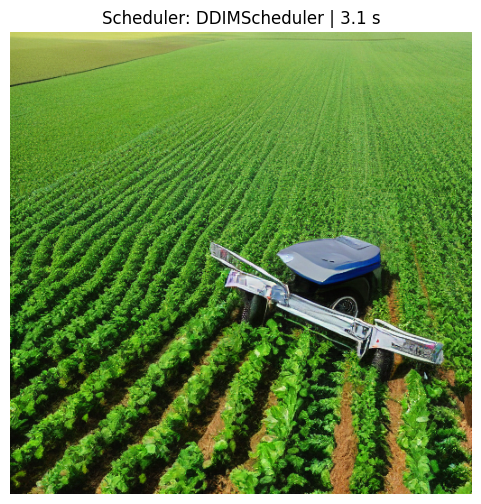

  0%|          | 0/20 [00:00<?, ?it/s]

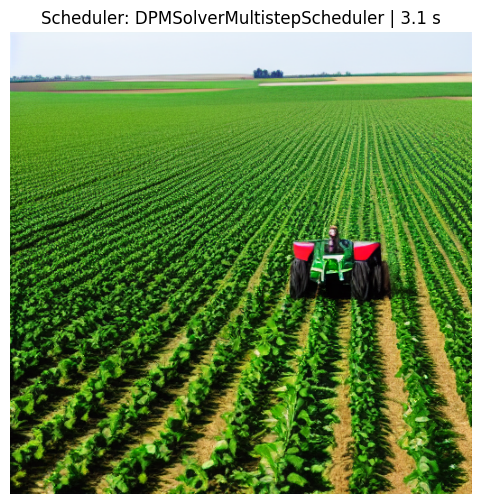

In [ ]:
# I choose a crop-monitoring scene to compare the two schedulers.
scheduler_prompt = (
    "A small agricultural robot moving between rows of green crops and checking plant growth, "
    "modern precision farming, natural daylight, realistic detailed photography"
)

# I generate one image with each scheduler while keeping the other settings the same.
for scheduler_cls in [DDIMScheduler, DPMSolverMultistepScheduler]:
    img, seconds = generate_image(
        scheduler_prompt,
        steps=BASE_STEPS,
        guidance=BASE_GUIDANCE,
        seed=1111,
        group="scheduler_comparison",
        tag=scheduler_cls.__name__,
        scheduler_cls=scheduler_cls,
    )
    show_image(img, f"Scheduler: {scheduler_cls.__name__} | {seconds:.1f} s")


## 10. Results table and export

I collect the settings and actual generation time from all experiments in a table. I also save the table as a CSV file so I can use the measured results in my practical report.


In [ ]:
# I convert my experiment records into a pandas DataFrame for easy comparison.
results_df = pd.DataFrame(experiment_records)
display(results_df[[
    "experiment", "tag", "steps", "guidance_scale", "seed", "scheduler", "time_seconds", "image_file"
]])
# I save the measured results so I can open them later in spreadsheet software.
results_csv = OUTPUT_DIR / "smart_agriculture_generation_results.csv"
results_df.to_csv(results_csv, index=False)
print("I saved my measured results to:", results_csv)


,experiment,tag,steps,guidance_scale,seed,scheduler,time_seconds,image_file
0,agriculture_dataset,drone_monitoring,20,7.5,2026,PNDMScheduler,6.60,smart_agriculture_outputs/agriculture_dataset_...
1,agriculture_dataset,drip_irrigation,20,7.5,2026,PNDMScheduler,3.12,smart_agriculture_outputs/agriculture_dataset_...
2,agriculture_dataset,smart_greenhouse,20,7.5,2026,PNDMScheduler,3.12,smart_agriculture_outputs/agriculture_dataset_...
3,agriculture_dataset,automated_harvesting,20,7.5,2026,PNDMScheduler,3.12,smart_agriculture_outputs/agriculture_dataset_...
4,negative_prompt,without_negative_prompt,20,7.5,314,PNDMScheduler,3.15,smart_agriculture_outputs/negative_prompt_with...
5,negative_prompt,with_negative_prompt,20,7.5,314,PNDMScheduler,3.15,smart_agriculture_outputs/negative_prompt_with...
6,inference_steps,steps_10,10,7.5,808,PNDMScheduler,1.77,smart_agriculture_outputs/inference_steps_step...
7,inference_steps,steps_20,20,7.5,808,PNDMScheduler,4.28,smart_agriculture_outputs/inference_steps_step...
8,inference_steps,steps_30,30,7.5,808,PNDMScheduler,5.63,smart_agriculture_outputs/inference_steps_step...
9,guidance_scale,guidance_3_0,20,3.0,909,PNDMScheduler,3.32,smart_agriculture_outputs/guidance_scale_guida...


I saved my measured results to: smart_agriculture_outputs/smart_agriculture_generation_results.csv


In [ ]:
# I prepare a separate table where I can rate the images after viewing them.
# I use 1 for poor, 3 for acceptable, and 5 for excellent.
quality_assessment_df = results_df[["experiment", "tag", "prompt", "steps", "guidance_scale", "scheduler", "image_file"]].copy()
quality_assessment_df["prompt_adherence_1_to_5"] = ""
quality_assessment_df["clarity_detail_1_to_5"] = ""
quality_assessment_df["artifacts_1_to_5"] = ""
quality_assessment_df["observations"] = ""
quality_csv = OUTPUT_DIR / "smart_agriculture_quality_assessment_to_complete.csv"
quality_assessment_df.to_csv(quality_csv, index=False)
display(quality_assessment_df.head(10))
print("I will fill in the ratings after checking each generated image.")


,experiment,tag,prompt,steps,guidance_scale,scheduler,image_file,prompt_adherence_1_to_5,clarity_detail_1_to_5,artifacts_1_to_5,observations
0,agriculture_dataset,drone_monitoring,A modern agricultural drone flying above a lar...,20,7.5,PNDMScheduler,smart_agriculture_outputs/agriculture_dataset_...,,,,
1,agriculture_dataset,drip_irrigation,A close view of a drip irrigation system water...,20,7.5,PNDMScheduler,smart_agriculture_outputs/agriculture_dataset_...,,,,
2,agriculture_dataset,smart_greenhouse,A modern smart greenhouse with rows of healthy...,20,7.5,PNDMScheduler,smart_agriculture_outputs/agriculture_dataset_...,,,,
3,agriculture_dataset,automated_harvesting,A modern agricultural harvesting machine worki...,20,7.5,PNDMScheduler,smart_agriculture_outputs/agriculture_dataset_...,,,,
4,negative_prompt,without_negative_prompt,A realistic photograph of a farmer inspecting ...,20,7.5,PNDMScheduler,smart_agriculture_outputs/negative_prompt_with...,,,,
5,negative_prompt,with_negative_prompt,A realistic photograph of a farmer inspecting ...,20,7.5,PNDMScheduler,smart_agriculture_outputs/negative_prompt_with...,,,,
6,inference_steps,steps_10,A farmer standing in a green crop field and ch...,10,7.5,PNDMScheduler,smart_agriculture_outputs/inference_steps_step...,,,,
7,inference_steps,steps_20,A farmer standing in a green crop field and ch...,20,7.5,PNDMScheduler,smart_agriculture_outputs/inference_steps_step...,,,,
8,inference_steps,steps_30,A farmer standing in a green crop field and ch...,30,7.5,PNDMScheduler,smart_agriculture_outputs/inference_steps_step...,,,,
9,guidance_scale,guidance_3_0,A smart irrigation system watering neat rows o...,20,3.0,PNDMScheduler,smart_agriculture_outputs/guidance_scale_guida...,,,,


I will fill in the ratings after checking each generated image.


## 11. Analysis and discussion

I answer these questions after running the notebook. I use my actual generated images and measured times instead of guessing the results.

1. **Prompt dataset:** Which agriculture prompt generated the image that matched its topic best? Mention at least two visible details.
2. **Negative prompt:** What differences did I notice between the two farmer images? Did the negative prompt reduce any unwanted details?
3. **Inference steps:** How did the generation time change from 10 to 20 to 30 steps? Did the image quality improve at the same rate?
4. **Guidance scale:** Which value gave the best balance between following the prompt and looking natural? What did I observe at the lowest and highest values?
5. **Scheduler:** How did DDIM and DPM-Solver differ in time, details, and unwanted artifacts?
6. **Fair comparison:** Why did I keep the seed and other settings constant when changing one parameter?

### Trends
- More inference steps often take more time, but the visual improvement may become smaller.
- A guidance scale changes how strongly the image follows the prompt. A very high value may not give the best-looking image.
- A negative prompt can discourage unwanted features, but it cannot fully control every detail.
- Scheduler performance depends on the model, prompt, seed, and settings.
- Generated agriculture images are visual concepts, not real measurements or proof of crop conditions.


## 12. Conclusion

After running the notebook and checking my images, I complete this conclusion using my actual results:

> In this practical, I used a pretrained Stable Diffusion model to generate images for smart agriculture. I created a small prompt dataset covering agricultural drones, drip irrigation, smart greenhouses, and automated harvesting. I also tested the effect of negative prompts, inference steps, guidance scale, and scheduler choice.  I learned that prompt writing and model settings affect the generated image. I also learned that I should compare the outputs using actual images and measured results.

### Limitations
- The image quality ratings are based on my own visual judgment.
- Generation time depends on the GPU or CPU, memory, software versions, and system load.
- A fixed seed helps me make a controlled comparison, but results may still differ across devices.
- I used only a small prompt dataset and a limited number of settings.
- The generated images are illustrative. They do not represent actual farm data or verified crop conditions.


## 13. References

1. Hugging Face, **Diffusers — Text-to-image generation**: https://huggingface.co/docs/diffusers/using-diffusers/conditional_image_generation
2. Hugging Face, **Diffusers — Schedulers**: https://huggingface.co/docs/diffusers/using-diffusers/schedulers
3. Hugging Face model card, **Stable Diffusion v1.5**: https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5
4. Rombach et al., **High-Resolution Image Synthesis with Latent Diffusion Models**, CVPR 2022: https://arxiv.org/abs/2112.10752
